# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнила студентка гр. 3381 Кунакова Мария Романовна. Вариант №11.

## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

Линейная стационарная дискретная система при нулевых начальных условиях описывается свёрткой входа с импульсной характеристикой:

$$y[n]=\sum_{k=-\infty}^{\infty}x[k]h[n-k],\qquad h[n]=\mathcal{S}\{\delta[n]\}.$$

Для причинной системы $h[n]=0$ при $n<0$. Рекурсивное звено второго порядка с $a_0=1$ задаётся уравнением

$$y[n]=b_0x[n]+b_1x[n-1]+b_2x[n-2]-a_1y[n-1]-a_2y[n-2].$$

Нулевые начальные условия означают $x[n]=y[n]=0$ при $n<0$. Передаточная функция имеет вид:

$$H(z)=\frac{Y(z)}{X(z)}=\frac{b_0+b_1z^{-1}+b_2z^{-2}}{1+a_1z^{-1}+a_2z^{-2}}.$$

Нули — корни $b_0z^2+b_1z+b_2=0$, полюса — корни $z^2+a_1z+a_2=0$. Если $z_i=r_i e^{j\theta_i}$, то $r_i=\sqrt{(\operatorname{Re}z_i)^2+(\operatorname{Im}z_i)^2}$, $\theta_i=\arg z_i$. Для причинной рациональной системы устойчивость по ограниченному входу и выходу обеспечивается расположением всех полюсов внутри единичного круга.

Частотная характеристика получается подстановкой $z=e^{j\hat{\omega}}$:

$$H(e^{j\hat{\omega}})=\sum_{n=0}^{\infty}h[n]e^{-j\hat{\omega}n},\quad A(\hat{\omega})=|H(e^{j\hat{\omega}})|,\quad \varphi(\hat{\omega})=\arg H(e^{j\hat{\omega}}).$$

Обозначения: $\nu=f/f_d$ — частота в циклах на отсчёт, $\hat{\omega}=2\pi\nu$ — угловая частота в радианах на отсчёт, $q=\hat{\omega}/\pi=2f/f_d$. Частота Найквиста соответствует $\nu=1/2$, $\hat{\omega}=\pi$ и $q=1$. Частотная характеристика периодична по $\hat{\omega}$ с периодом $2\pi$.

Для последовательности длины $N$ используются прямое и обратное ДПФ:

$$X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N},\qquad x[n]=\frac{1}{N}\sum_{k=0}^{N-1}X[k]e^{j2\pi kn/N}.$$

Частоты отсчётов ДПФ: $\nu_k=k/N$, $f_k=kf_d/N$. В представлении $0\le k<N$ индексы $k>N/2$ соответствуют отрицательным частотам $f_k=(k-N)f_d/N$ с учётом периодичности спектра. Для вещественного входа $X[N-k]=X^*[k]$. Коэффициенты ряда Фурье периодического продолжения равны $C[k]=X[k]/N$.

Для конечного фрагмента непрерывная по частоте функция

$$X_F(\nu)=\sum_{n=0}^{N-1}x[n]e^{-j2\pi\nu n}$$

является дискретно-временным преобразованием Фурье (ДВПФ, DTFT); $X[k]=X_F(k/N)$. ДПФ после дополнения нулями даёт более густую выборку той же функции $X_F(\nu)$.

Периодический аналоговый сигнал восстанавливается по формуле задания:

$$x(t)=\frac1N\sum_{k=-N/2}^{N/2-1}X_a[k]e^{j2\pi kt/(NT)},\qquad T=1/f_d.$$

Здесь $X_a[k]=X[N+k]$ при $k<0$ и $X_a[k]=X[k]$ при $k\ge0$. Двусторонние спектральные коэффициенты аналогового сигнала равны $C_a[k]=X_a[k]/N$; для пары линий вещественной косинусоиды её амплитуда равна $2|C_a[k]|$. В строгом смысле спектр периодического аналогового сигнала состоит из дельта-линий с этими коэффициентами.

Для принятой нормировки ДПФ равенство Парсеваля имеет вид

$$\sum_{n=0}^{N-1}|x[n]|^2=\frac1N\sum_{k=0}^{N-1}|X[k]|^2.$$


## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

## Выполнение работы

### Подготовка параметров

In [1]:
import cmath
import numpy as np
import matplotlib.pyplot as plt

# Вариант 11
N_var = 11

# Часть 1
b0 = 0.5 + 0.02 * N_var
b1 = b0 * ((-1)**(N_var + 1)) * (0.9822 + 0.0178 * N_var)
b2 = b0 * (0.8 + 0.2 * (N_var % 5))
a0 = 1
a1 = ((-1)**N_var) * (0.7778 + 0.025 * N_var)
a2 = 0.64 + 0.006 * N_var
N1 = (N_var % 10) + 20
N2 = (N_var % 10) + 30
fd_1 = 1000 * N_var

# Часть 2
N = 64
fd_2 = 2000 * (N_var % 5 + 1)
T = 1 / fd_2
A1 = 1 + 0.01 * N_var
A2 = 2 * A1
f1 = fd_2 / 8
f2 = 1.5 * f1

print(f'b = [{b0:.5f}, {b1:.5f}, {b2:.5f}]')
print(f'a = [{a0}, {a1:.5f}, {a2:.5f}]')
print(f'N1={N1}, N2={N2}, fd1={fd_1} Гц')
print(f'N={N}, fd2={fd_2} Гц, T={T} с')
print(f'A1={A1}, A2={A2}, f1={f1} Гц, f2={f2} Гц')

b = [0.72000, 0.84816, 0.72000]
a = [1, -1.05280, 0.70600]
N1=21, N2=31, fd1=11000 Гц
N=64, fd2=4000 Гц, T=0.00025 с
A1=1.11, A2=2.22, f1=500.0 Гц, f2=750.0 Гц


### Часть 1

#### 1. Импульсная характеристика

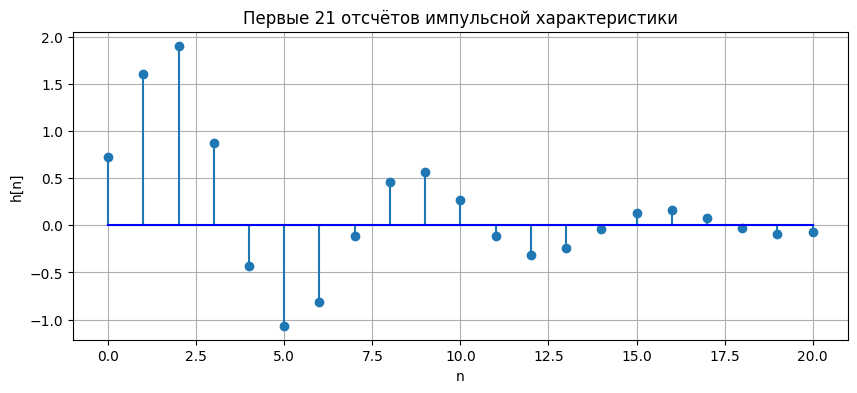

Первые три отсчёта h: [0.72       1.606176   1.90266209]


In [2]:
# Формирование дискретного дельта-импульса
delta = np.zeros(N1)
delta[0] = 1

# Расчет импульсной характеристики по разностному уравнению
h = np.zeros(N1)
for n in range(N1):
    h[n] = (b0 * delta[n]
            + (b1 * delta[n-1] if n >= 1 else 0)
            + (b2 * delta[n-2] if n >= 2 else 0)
            - (a1 * h[n-1] if n >= 1 else 0)
            - (a2 * h[n-2] if n >= 2 else 0))

plt.figure(figsize=(10, 4))
plt.stem(np.arange(N1), h, basefmt='b-')
plt.title(f'Первые {N1} отсчётов импульсной характеристики')
plt.xlabel('n')
plt.ylabel('h[n]')
plt.grid(True)
plt.show()
print('Первые три отсчёта h:', h[:3])

##### Анализ

При подаче единичного дискретного импульса и нулевых начальных условиях получено $h[0]=0.72$, $h[1]=1.606176$, $h[2]=1.90266209$. Разностное уравнение для импульсной характеристики имеет вид:

$$h[n]=0.72\delta[n]+0.84816\delta[n-1]+0.72\delta[n-2]+1.0528h[n-1]-0.706h[n-2],$$

где $h[-1]=h[-2]=0$. При $n\ge3$ остаётся однородная рекуррентная часть.

Аналитическая формула через полюса $p_1,p_2$:

$$g[n]=\begin{cases}\dfrac{p_1^{n+1}-p_2^{n+1}}{p_1-p_2},&n\ge0,\\0,&n<0,\end{cases}\qquad h[n]=0.72g[n]+0.84816g[n-1]+0.72g[n-2].$$

Эквивалентна вещественная запись

$$h[0]=0.72,$$
$$h[n]=r^{n-1}\left(1.606176\cos((n-1)\theta)+1.6142310546\sin((n-1)\theta)\right),\quad n\ge1,$$

где $r=\sqrt{0.706}\approx0.84023806$, $\theta=\arccos(1.0528/(2r))\approx0.28449129\pi$.

График содержит первые $N_1=21$ отсчёт, $0\le n\le20$. Импульсная характеристика представляет собой затухающие колебания. Её действительная длина бесконечна: полюса не сокращаются с нулями, и характеристика не обрывается на $n=20$. Значение $N_1$ определяет длину вычисленного фрагмента, а не полную длительность реакции системы.


#### 2. Реакция через свертку.

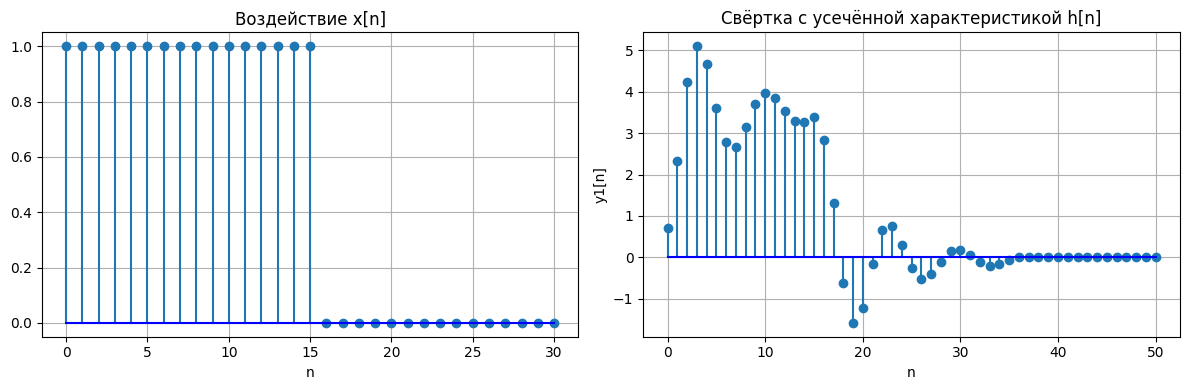

Длина массива входа: 31
Длительность ненулевой части входа: 16
Длина массива свёртки: 51
Длина ненулевой части свёртки: 36


In [3]:
# Формирование прямоугольного импульса x[n]
x = np.zeros(N2)
half_N2 = int(np.round(N2 / 2))
x[:half_N2] = 1

# Расчет линейной свертки
len_y1 = N1 + N2 - 1
y1 = np.zeros(len_y1)
for n in range(len_y1):
    for k in range(N2):
        # Проверка выхода индекса за границы массива h
        if 0 <= n-k < N1:
            y1[n] += x[k] * h[n-k]
n_y1 = np.arange(len_y1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.stem(np.arange(N2), x, basefmt='b-')
plt.title('Воздействие x[n]')
plt.xlabel('n')
plt.grid(True)
plt.subplot(1, 2, 2)
plt.stem(n_y1, y1, basefmt='b-')
plt.title('Свёртка с усечённой характеристикой h[n]')
plt.xlabel('n')
plt.ylabel('y1[n]')
plt.grid(True)
plt.tight_layout()
plt.show()

print('Длина массива входа:', len(x))
print('Длительность ненулевой части входа:', half_N2)
print('Длина массива свёртки:', len(y1))
print('Длина ненулевой части свёртки:', half_N2 + N1 - 1)

##### Анализ

При $N_2=31$ округление $N_2/2=15.5$ даёт $L=16$. Поэтому $x[n]=1$ для $n=0,\ldots,15$ и $x[n]=0$ для $n=16,\ldots,30$.

a) Длина заданного массива входа равна 31 отсчёту, а длительность ненулевой части прямоугольного импульса — 16 отсчётов.

b) Полная длина массива свертки с усечённой характеристикой $h_{21}[n]$ аналитически равна $N_1+N_2-1=21+31-1=51$ отсчету. Но последние 15 отсчётов входа нулевые, поэтому ненулевая часть результата ограничена $0\le n\le35$ и имеет длину $21+16-1=36$ отсчётов. На графике отсчёты $n=36,\ldots,50$ равны нулю.

c) Ограничение результата первыми $N_2$ отсчётами выбирает тот же интервал наблюдения, что и при расчёте по разностному уравнению. Это применяется для корректного сравнения методов. Истинная реакция рекурсивной системы на конечный импульс имеет бесконечный затухающий хвост, который отбрасывается при таком ограничении.

#### 3. Реакция по разностному уравнению

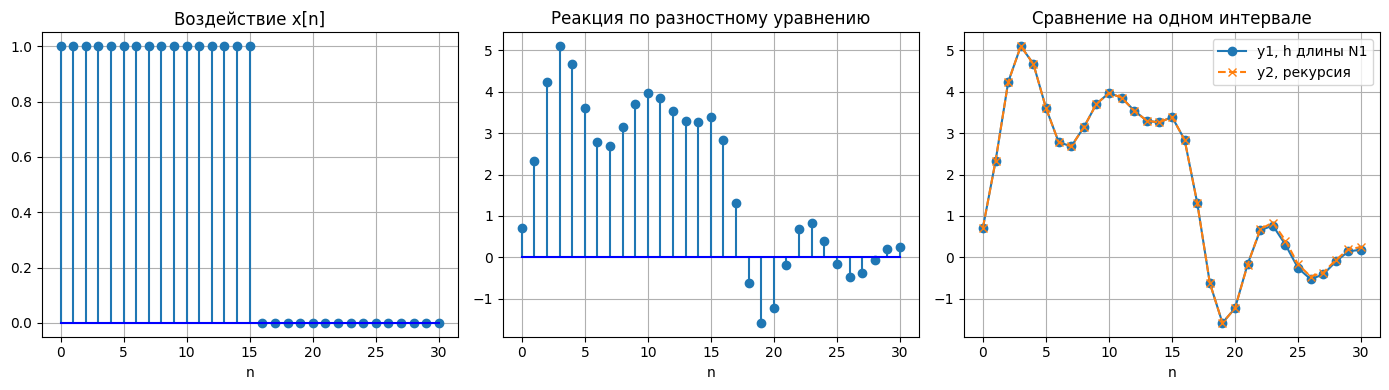

Разница на первых N1 отсчётах: 8.881784197001252e-16
Разница на первых N2 отсчётах: 0.0993392148655825
Разница при достаточной длине h: 8.881784197001252e-16


In [4]:
# Решение разностного уравнения для воздействия x[n]
y2 = np.zeros(N2)
for n in range(N2):
    # Вычисление текущего отсчета с учетом предыдущих (нулевые начальные условия)
    y2[n] = (b0 * x[n]
             + (b1 * x[n-1] if n >= 1 else 0)
             + (b2 * x[n-2] if n >= 2 else 0)
             - (a1 * y2[n-1] if n >= 1 else 0)
             - (a2 * y2[n-2] if n >= 2 else 0))

# Построение графиков для сравнения
plt.figure(figsize=(14, 4))
plt.subplot(1, 3, 1)
plt.stem(np.arange(N2), x, basefmt='b-')
plt.title('Воздействие x[n]')
plt.xlabel('n')
plt.grid(True)
plt.subplot(1, 3, 2)
plt.stem(np.arange(N2), y2, basefmt='b-')
plt.title('Реакция по разностному уравнению')
plt.xlabel('n')
plt.grid(True)
plt.subplot(1, 3, 3)
plt.plot(np.arange(N2), y1[:N2], 'o-', label='y1, h длины N1')
plt.plot(np.arange(N2), y2, 'x--', label='y2, рекурсия')
plt.title('Сравнение на одном интервале')
plt.xlabel('n')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print('Разница на первых N1 отсчётах:', np.max(np.abs(y1[:N1]-y2[:N1])))
print('Разница на первых N2 отсчётах:', np.max(np.abs(y1[:N2]-y2)))

# Расчет h[n] длиной N2 для точного совпадения
h_check = np.zeros(N2)
delta_check = np.zeros(N2)
delta_check[0] = 1
for n in range(N2):
    h_check[n] = (b0 * delta_check[n]
                  + (b1 * delta_check[n-1] if n >= 1 else 0)
                  + (b2 * delta_check[n-2] if n >= 2 else 0)
                  - (a1 * h_check[n-1] if n >= 1 else 0)
                  - (a2 * h_check[n-2] if n >= 2 else 0))

y_check = np.zeros(N2)
for n in range(N2):
    for k in range(n+1):
        y_check[n] += x[k] * h_check[n-k]
print('Разница при достаточной длине h:', np.max(np.abs(y_check-y2)))

##### Анализ

Разностное уравнение рекурсивного звена 2-го порядка имеет вид

$$y_2[n]=0.72x[n]+0.84816x[n-1]+0.72x[n-2]+1.0528y_2[n-1]-0.706y_2[n-2],$$

где $x[n]=y_2[n]=0$ при $n<0$. Входной массив и рассчитанный фрагмент реакции имеют по $N_2=31$ отсчёту, $n=0,\ldots,30$. Ненулевая часть входа содержит 16 отсчётов. Физическая длина реакции бесконечна, после выключения входа выход продолжает колебаться из-за памяти системы.

Первые 21 отсчёт $y_1$ и $y_2$, то есть $0\le n\le20$, совпадают с точностью округления. Начиная с $n=21$, при свёртке отсутствуют слагаемые, содержащие $h[21],h[22],\ldots$, поэтому появляется различие. Максимальная разность на интервале $0\le n\le30$ равна примерно $9.9339\cdot10^{-2}$; это ошибка усечения характеристики.


#### 4. Нули и полюса передаточной функции

In [5]:
# Функция для поиска корней квадратного уравнения az^2 + bz + c = 0
def manual_roots(a, b, c):
    D = b*b - 4*a*c
    return np.array([(-b+cmath.sqrt(D))/(2*a),
                     (-b-cmath.sqrt(D))/(2*a)])

# Нули - корни числителя, полюса - корни знаменателя
zeros = manual_roots(b0, b1, b2)
poles = manual_roots(a0, a1, a2)

# Вывод в алгебраической и показательной формах
for label, roots in [('Нули', zeros), ('Полюса', poles)]:
    print(label)
    for root in roots:
        print(f'{root:.8f} = {abs(root):.8f} exp(j ({np.angle(root)/np.pi:.8f}) pi)')
print('K =', b0/a0)

Нули
-0.58900000+0.80813303j = 1.00000000 exp(j (0.70047821) pi)
-0.58900000-0.80813303j = 1.00000000 exp(j (-0.70047821) pi)
Полюса
0.52640000+0.65490689j = 0.84023806 exp(j (0.28449129) pi)
0.52640000-0.65490689j = 0.84023806 exp(j (-0.28449129) pi)
K = 0.72


##### Анализ

Передаточная функция:

$$H(z)=\frac{0.72+0.84816z^{-1}+0.72z^{-2}}{1-1.0528z^{-1}+0.706z^{-2}}.$$

Нули и полюса в алгебраической и показательной формах:

$$z_{1,2}=-0.589\pm j0.80813303=e^{\pm j0.70047821\pi},$$
$$p_{1,2}=0.5264\pm j0.65490689=0.84023806e^{\pm j0.28449129\pi}.$$

Алгебраическая и показательная формы связаны равенством $r(\cos\theta+j\sin\theta)=re^{j\theta}$. В каждой паре корни комплексно-сопряжённые, поскольку коэффициенты соответствующего многочлена вещественные. Модули сопряжённых корней одинаковы, а аргументы противоположны.

Передаточная функция в виде произведения простейших множителей:

$$H(z)=0.72\frac{(1-e^{j0.70047821\pi}z^{-1})(1-e^{-j0.70047821\pi}z^{-1})}{(1-0.84023806e^{j0.28449129\pi}z^{-1})(1-0.84023806e^{-j0.28449129\pi}z^{-1})}.$$

Множитель $K=b_0/a_0=0.72$.


#### 5. Карта нулей и полюсов.

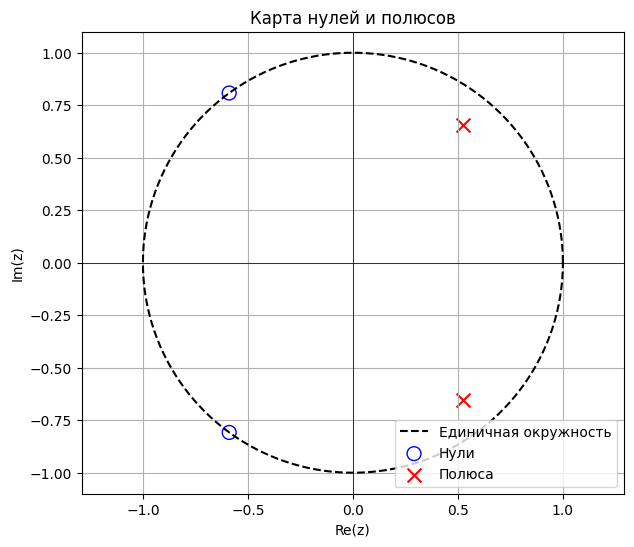

Модули полюсов: [0.84023806 0.84023806]
Остатки числителя: [1.57009246e-16 1.57009246e-16]
Остатки знаменателя: [0. 0.]


In [6]:
# Построение единичной окружности
theta = np.linspace(0, 2*np.pi, 500)
plt.figure(figsize=(7, 6))
plt.plot(np.cos(theta), np.sin(theta), 'k--', label='Единичная окружность')

# Отображение нулей (кружки) и полюсов (крестики)
plt.scatter(zeros.real, zeros.imag, marker='o', facecolors='none',
            edgecolors='b', s=100, label='Нули')
plt.scatter(poles.real, poles.imag, marker='x', color='r', s=100, label='Полюса')

plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.xlabel('Re(z)')
plt.ylabel('Im(z)')
plt.title('Карта нулей и полюсов')
plt.axis('equal')
plt.grid(True)
plt.legend(loc='lower right')
plt.show()

# Проверка подстановкой корней
print('Модули полюсов:', np.abs(poles))
print('Остатки числителя:', np.abs(b0*zeros**2+b1*zeros+b2))
print('Остатки знаменателя:', np.abs(a0*poles**2+a1*poles+a2))

##### Анализ

Оба нуля лежат на единичной окружности, а оба полюса расположены внутри неё. Модули полюсов равны $0.84023806<1$.

a) Поскольку все полюса лежат внутри единичной окружности, причинное рекурсивное звено устойчиво: импульсная характеристика абсолютно суммируема, собственные колебания затухают.

b) Положение точек на графике полностью совпадает с вычисленными в п. 4 значениями нулей и полюсов.

#### 6. АЧХ и ФЧХ в шкале нормированных частот.

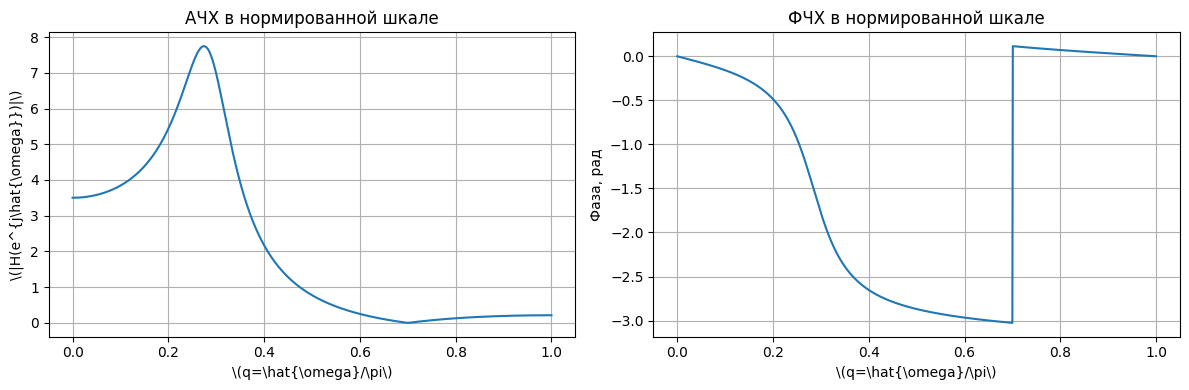

Координата нуля q: 0.7004782068764306
H при нулевой частоте: 3.5030006123698705
H при частоте Найквиста: 0.21452805567638106


In [7]:
# Расчет АЧХ и ФЧХ через подстановку z = exp(j*w)
# w_norm - угловая частота в рад/отсчёт; q = w_norm/pi.
w_norm = np.linspace(0, np.pi, 1024)
q = w_norm / np.pi
z_inv = np.exp(-1j*w_norm)

# Вычисление передаточной функции
h_freq = (b0+b1*z_inv+b2*z_inv**2) / (a0+a1*z_inv+a2*z_inv**2)
AFC = np.abs(h_freq)
PFC = np.unwrap(np.angle(h_freq))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(q, AFC)
plt.title('АЧХ в нормированной шкале')
plt.xlabel(r'\(q=\hat{\omega}/\pi\)')
plt.ylabel(r'\(|H(e^{j\hat{\omega}})|\)')
plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(q, PFC)
plt.title('ФЧХ в нормированной шкале')
plt.xlabel(r'\(q=\hat{\omega}/\pi\)')
plt.ylabel('Фаза, рад')
plt.grid(True)
plt.tight_layout()
plt.show()

print('Координата нуля q:', np.abs(np.angle(zeros[0]))/np.pi)
print('H при нулевой частоте:', AFC[0])
print('H при частоте Найквиста:', AFC[-1])

##### Анализ

a) Границы основной полосы частот: $\hat{\omega}\in[0,\pi]$ или $q=\hat{\omega}/\pi \in [0,1]$. Полная основная полоса: $-\pi\le\hat{\omega}<\pi$.

b) Полюса, расположенные близко к единичной окружности, создают резонансный подъём АЧХ. Максимум находится при $q\approx0.274$. Нуль на единичной окружности при $q\approx0.7$ приводит к $|H|=0$.

c) Скачок ФЧХ на $\pi$ соответствует нулю АЧХ (частоте полного подавления), где фаза не определена.

d) На постоянном сигнале коэффициент передачи $|H(1)|\approx3.503$, на частоте Найквиста $|H(-1)|\approx0.21453$. Преимущественно подавляются высокочастотные составляющие.


#### 7. АЧХ и ФЧХ в шкале абсолютных частот.

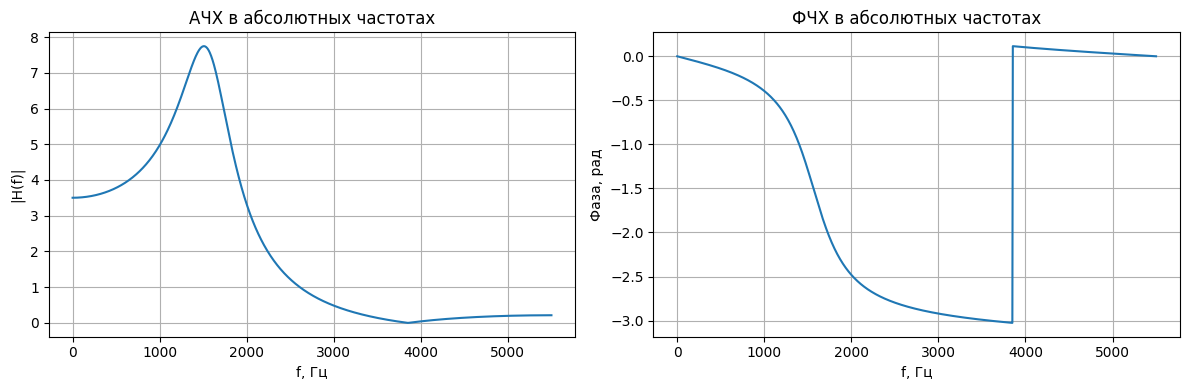

In [8]:
# Перевод нормированной частоты в абсолютную (Гц)
f_abs = w_norm * fd_1 / (2*np.pi)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(f_abs, AFC)
plt.xlabel('f, Гц')
plt.ylabel('|H(f)|')
plt.title('АЧХ в абсолютных частотах')
plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(f_abs, PFC)
plt.xlabel('f, Гц')
plt.ylabel('Фаза, рад')
plt.title('ФЧХ в абсолютных частотах')
plt.grid(True)
plt.tight_layout()
plt.show()

##### Анализ

a) При $f_{d1}=11000$ Гц основная полоса частот:  $0\le f\le5500$ Гц (до частоты Найквиста). Полная полоса: $-5500\le f<5500$ Гц.

b) Связь частот:

$$f=\frac{\hat{\omega}}{2\pi}f_{d1}=\frac{qf_{d1}}2=5500q,\qquad \hat{\omega}=\frac{2\pi f}{f_{d1}}.$$

Резонансный максимум $q\approx0.27427$ соответствует примерно 1508 Гц. Нуль $q\approx0.70047821$ соответствует примерно 3852 Гц. Форма графиков идентична п. 6, масштаб оси абсцисс переведён в герцы.


### Часть 2

#### 1. Графики последовательности x(n)

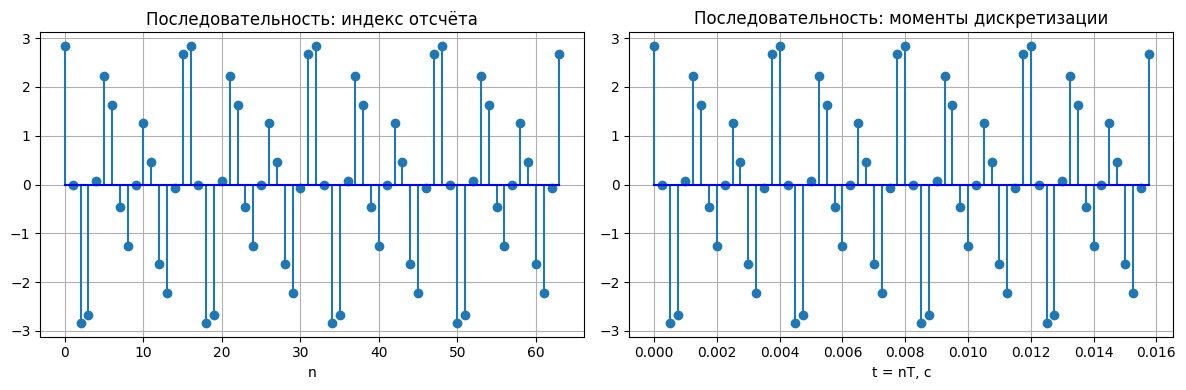

In [9]:
# Формирование дискретной последовательности (сумма двух гармоник)
n = np.arange(N)
t_n = n*T
x_n = (A1*np.cos(2*np.pi*f1*t_n+np.pi/4)
       + A2*np.cos(2*np.pi*f2*t_n+np.pi/8))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.stem(n, x_n, basefmt='b-')
plt.xlabel('n')
plt.title('Последовательность: индекс отсчёта')
plt.grid(True)
plt.subplot(1, 2, 2)
plt.stem(t_n, x_n, basefmt='b-')
plt.xlabel('t = nT, с')
plt.title('Последовательность: моменты дискретизации')
plt.grid(True)
plt.tight_layout()
plt.show()

##### Анализ

Последовательность задаётся выражением

$$x[n]=1.11\cos\left(\frac{\pi n}{4}+\frac\pi4\right)+2.22\cos\left(\frac{3\pi n}{8}+\frac\pi8\right).$$

Первый график показывает значения при целочисленных индексах $n=0,\ldots,63$, второй — в моменты $t_n=nT$, от 0 до $63T=0.01575$ с.

Первая гармоника имеет период 8 отсчётов, вторая — 16 отсчётов. Наименьший период их суммы равен 16 отсчётам (0.004 с). Заданное $N=64$ содержит четыре минимальных периода.



#### 2. ОДПФ от ДПФ

Максимальная мнимая часть: 3.0133983389287606e-14
Максимальная ошибка восстановления: 2.3092638912203256e-14


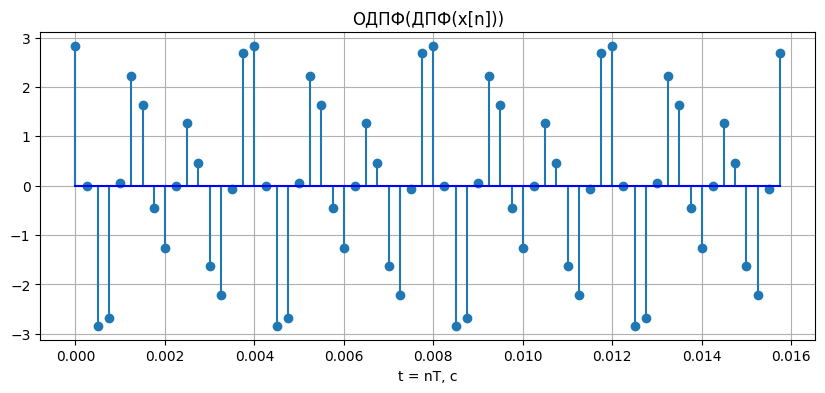

In [10]:
# Реализация прямого ДПФ (матричный метод)
def manual_dft(x):
    N_x = len(x)
    n_idx = np.arange(N_x)
    k_idx = np.arange(N_x)
    # Формирование матрицы базисных функций exp(-j*2*pi*k*n/N)
    W = np.exp(-1j*2*np.pi*np.outer(k_idx, n_idx)/N_x)
    return W @ x

# Реализация обратного ДПФ
def manual_idft(X):
    N_x = len(X)
    n_idx = np.arange(N_x)
    k_idx = np.arange(N_x)
    # Формирование обратной матрицы exp(j*2*pi*k*n/N)
    W_inv = np.exp(1j*2*np.pi*np.outer(n_idx, k_idx)/N_x)
    return (W_inv @ X) / N_x

# Вычисление ДПФ и ОДПФ
X_k = manual_dft(x_n)
x_rec_complex = manual_idft(X_k)
print('Максимальная мнимая часть:', np.max(np.abs(x_rec_complex.imag)))
x_rec = x_rec_complex.real
print('Максимальная ошибка восстановления:', np.max(np.abs(x_n-x_rec)))

plt.figure(figsize=(10, 4))
plt.stem(t_n, x_rec, basefmt='b-')
plt.xlabel('t = nT, с')
plt.title('ОДПФ(ДПФ(x[n]))')
plt.grid(True)
plt.show()

##### Анализ

Прямое ДПФ вычислено с отрицательным знаком в экспоненте, обратное — с положительным знаком и множителем $1/N$. Применение ОДПФ к $X[k]=\operatorname{DFT}\{x[n]\}$ восстанавливает исходные 64 отсчёта. Максимальная ошибка восстановления составляет $2.3093\cdot10^{-14}$. Это соответствует накоплению ошибок арифметики с плавающей точкой.

#### 3. Амплитудный и фазовый спектры

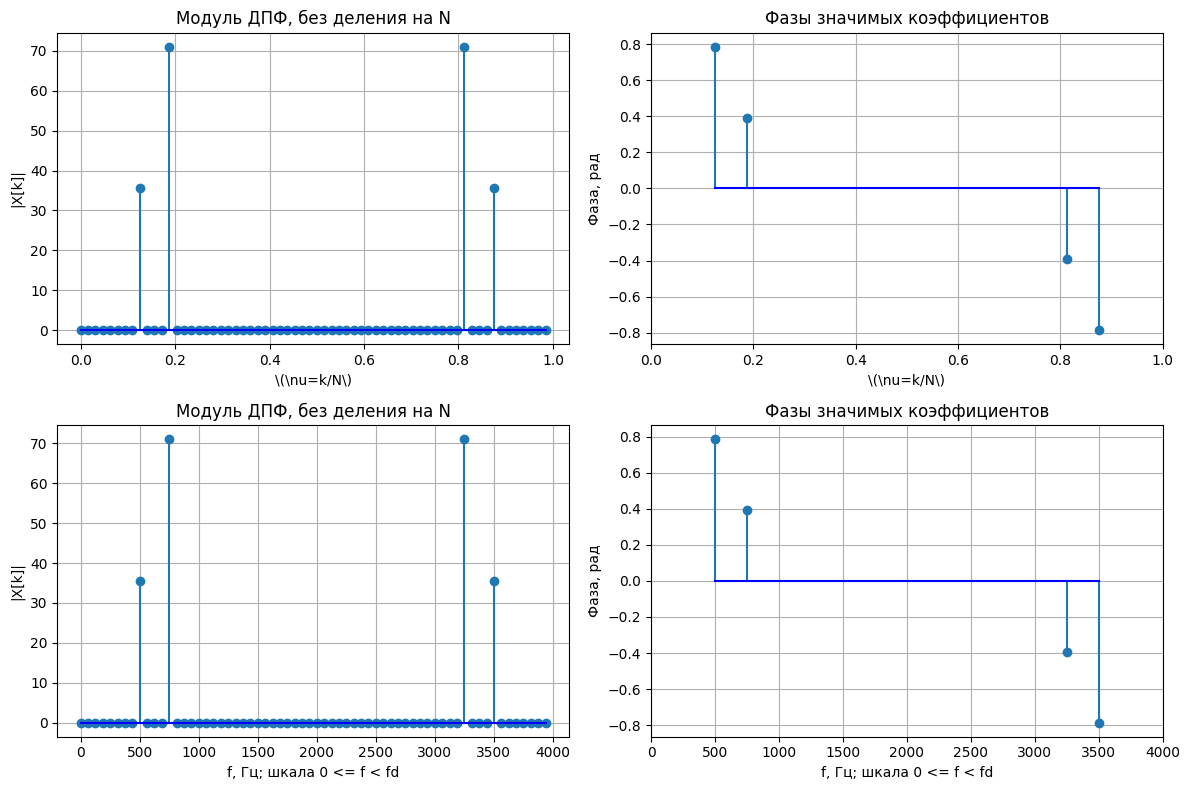

Значимые коэффициенты: k, |X[k]|, фаза/pi
8 35.519999999999996 0.24999999999999992
12 71.03999999999999 0.12499999999999992
52 71.04000000000005 -0.12499999999999717
56 35.52000000000015 -0.24999999999999717


In [11]:
# Выделение модуля и фазы спектра
X_mag = np.abs(X_k)
X_phase = np.angle(X_k)

# Формирование частотных осей
f_norm = np.arange(N)/N
f_abs_2 = f_norm*fd_2

# Маска для отображения фаз только значимых (ненулевых) коэффициентов
phase_mask = X_mag > 1e-10*np.max(X_mag)

plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.stem(f_norm, X_mag, basefmt='b-')
plt.title('Модуль ДПФ, без деления на N')
plt.xlabel(r'\(\nu=k/N\)')
plt.ylabel('|X[k]|')
plt.grid(True)
plt.subplot(2, 2, 2)
plt.stem(f_norm[phase_mask], X_phase[phase_mask], basefmt='b-')
plt.title('Фазы значимых коэффициентов')
plt.xlabel(r'\(\nu=k/N\)')
plt.ylabel('Фаза, рад')
plt.xlim(0, 1)
plt.grid(True)
plt.subplot(2, 2, 3)
plt.stem(f_abs_2, X_mag, basefmt='b-')
plt.title('Модуль ДПФ, без деления на N')
plt.xlabel('f, Гц; шкала 0 <= f < fd')
plt.ylabel('|X[k]|')
plt.grid(True)
plt.subplot(2, 2, 4)
plt.stem(f_abs_2[phase_mask], X_phase[phase_mask], basefmt='b-')
plt.title('Фазы значимых коэффициентов')
plt.xlabel('f, Гц; шкала 0 <= f < fd')
plt.ylabel('Фаза, рад')
plt.xlim(0, fd_2)
plt.grid(True)
plt.tight_layout()
plt.show()

print('Значимые коэффициенты: k, |X[k]|, фаза/pi')
for k in np.flatnonzero(phase_mask):
    print(k, X_mag[k], X_phase[k]/np.pi)

##### Анализ

a) Связь времени: $t_n=nT$; нормирование этого времени на $T$ даёт индекс $n$.

b) Связь частот: $f_k=\nu_k f_{d2}=kf_{d2}/N$. Угловая частота в радианах на отсчёт равна $2\pi k/N$. Шаг сетки $\Delta f=62.5$ Гц.

c) Частоты гармоник точно совпадают с узлами ДПФ: $k_1=500/62.5=8$, $k_2=750/62.5=12$.

d) В точной арифметике имеются только четыре ненулевых коэффициента:

| $k$ | $k/N$ | $kf_{d2}/N$, Гц | Эквивалентная знаковая частота, Гц | $|X[k]|$ | $\arg X[k]$ |
|---:|---:|---:|---:|---:|---:|
| 8 | 0.125 | 500 | 500 | 35.52 | $\pi/4$ |
| 12 | 0.1875 | 750 | 750 | 71.04 | $\pi/8$ |
| 52 | 0.8125 | 3250 | −750 | 71.04 | $-\pi/8$ |
| 56 | 0.875 | 3500 | −500 | 35.52 | $-\pi/4$ |

Спектр сопряжённо-симметричен. Амплитуды косинусоид восстанавливаются как $2|X[k_i]|/N$. Остальные коэффициенты теоретически нулевые, и их фаза не определена.

#### 4. Модуль ДПФ конечной последовательности

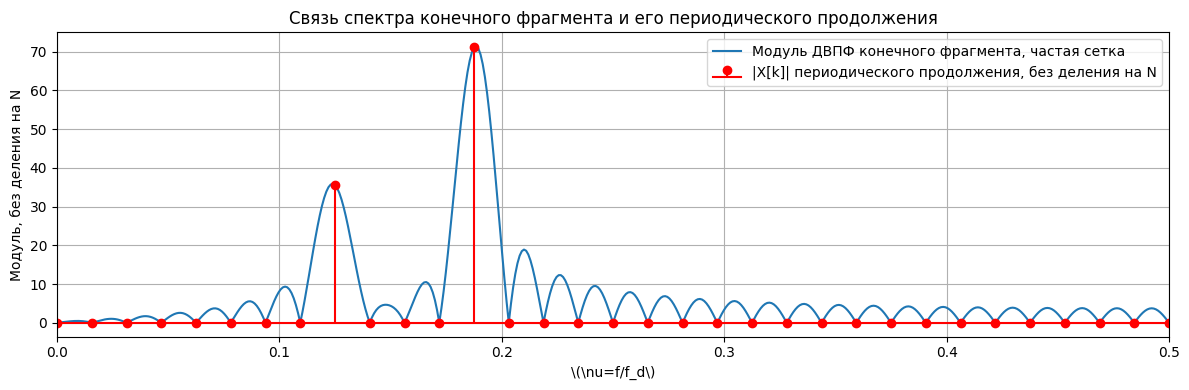

Совпадение исходных узлов: 0.0


In [12]:
# Дополнение нулями до N_pad = 1024 для густой сетки частот
N_pad = 1024
x_pad = np.pad(x_n, (0, N_pad-N))
# Вычисление ДПФ дополненного сигнала
X_pad = manual_dft(x_pad)
f_pad_norm = np.arange(N_pad)/N_pad

plt.figure(figsize=(12, 4))
plt.plot(f_pad_norm, np.abs(X_pad),
         label='Модуль ДВПФ конечного фрагмента, частая сетка')
plt.stem(f_norm, X_mag, linefmt='r-', markerfmt='ro', basefmt='r-',
         label='|X[k]| периодического продолжения, без деления на N')
plt.xlabel(r'\(\nu=f/f_d\)')
plt.ylabel('Модуль, без деления на N')
plt.title('Связь спектра конечного фрагмента и его периодического продолжения')
plt.xlim(0, 0.5)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Проверка совпадения ДПФ на исходных 64 узлах
print('Совпадение исходных узлов:', np.max(np.abs(X_pad[::(N_pad//N)]-X_k)))

##### Анализ

Функция $X_F(\nu)=\sum_{n=0}^{63}x[n]e^{-j2\pi\nu n}$ непрерывна по частоте и периодична с периодом 1. Её значения в узлах $\nu=k/64$ совпадают с $X[k]$. Дополнение нулями до $M=1024$ отсчётов не меняет исходный конечный фрагмент и даёт значения той же функции $X_F(\nu)$ на более густой сетке $\nu=m/1024$. Каждый шестнадцатый отсчёт дополненного ДПФ совпадает с исходным $X[k]$.

Модуль ДПФ конечной последовательности представляет собой дискретную выборку (отсчёты) непрерывного амплитудного спектра ДВПФ. Дополнение нулями уплотняет частотную сетку (интерполяция), но не добавляет новой информации и не повышает разрешающую способность.

#### 5. Восстановление аналогового сигнала

Максимальная мнимая часть x(t): 3.334020365347304e-14


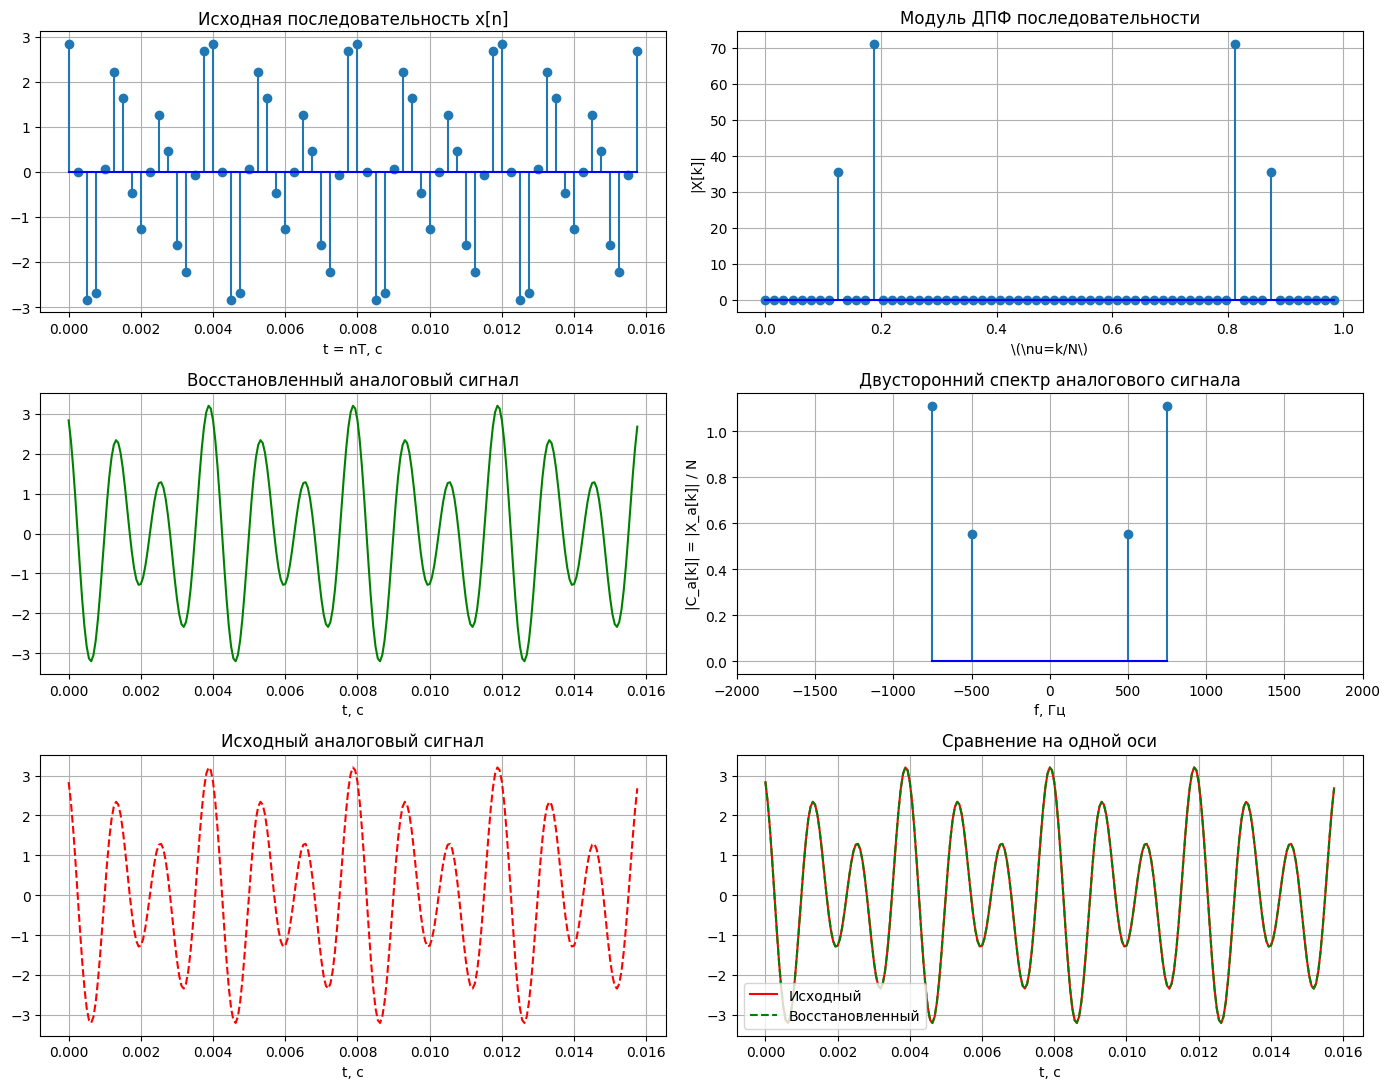

Число точек сетки восстановления: 253
Максимальная ошибка x(t): 4.005129561335252e-14


In [13]:
# Формирование временной сетки с шагом 0.25T
t_rec = np.arange(4*(N-1)+1) * (T/4)
# Перестановка индексов в знаковую шкалу
k_shift = np.arange(-N//2, N//2)
X_a = np.zeros(N, dtype=complex)
for i, k in enumerate(k_shift):
    X_a[i] = X_k[N+k] if k < 0 else X_k[k]

# Восстановление сигнала по формуле суммы
x_t_rec_complex = np.zeros(t_rec.size, dtype=complex)
for i, t_val in enumerate(t_rec):
    sum_val = 0j
    for j, k_val in enumerate(k_shift):
        sum_val += X_a[j]*np.exp(1j*2*np.pi*k_val*t_val/(N*T))
    x_t_rec_complex[i] = sum_val/N

print('Максимальная мнимая часть x(t):', np.max(np.abs(x_t_rec_complex.imag)))
x_t_rec = x_t_rec_complex.real

# Исходный аналоговый сигнал для сравнения
x_t_orig = (A1*np.cos(2*np.pi*f1*t_rec+np.pi/4)
            + A2*np.cos(2*np.pi*f2*t_rec+np.pi/8))

# Коэффициенты аналогового спектра и маска значимых
C_a = X_a/N
f_a = k_shift/(N*T)
mask_a = np.abs(C_a) > 1e-10*np.max(np.abs(C_a))

plt.figure(figsize=(14, 11))
plt.subplot(3, 2, 1)
plt.stem(t_n, x_n, basefmt='b-')
plt.title('Исходная последовательность x[n]')
plt.xlabel('t = nT, с')
plt.grid(True)
plt.subplot(3, 2, 2)
plt.stem(f_norm, X_mag, basefmt='b-')
plt.title('Модуль ДПФ последовательности')
plt.xlabel(r'\(\nu=k/N\)')
plt.ylabel('|X[k]|')
plt.grid(True)
plt.subplot(3, 2, 3)
plt.plot(t_rec, x_t_rec, 'g-')
plt.title('Восстановленный аналоговый сигнал')
plt.xlabel('t, с')
plt.grid(True)
plt.subplot(3, 2, 4)
plt.stem(f_a[mask_a], np.abs(C_a[mask_a]), basefmt='b-')
plt.title('Двусторонний спектр аналогового сигнала')
plt.xlabel('f, Гц')
plt.ylabel('|C_a[k]| = |X_a[k]| / N')
plt.xlim(-fd_2/2, fd_2/2)
plt.grid(True)
plt.subplot(3, 2, 5)
plt.plot(t_rec, x_t_orig, 'r--')
plt.title('Исходный аналоговый сигнал')
plt.xlabel('t, с')
plt.grid(True)
plt.subplot(3, 2, 6)
plt.plot(t_rec, x_t_orig, 'r-', label='Исходный')
plt.plot(t_rec, x_t_rec, 'g--', label='Восстановленный')
plt.title('Сравнение на одной оси')
plt.xlabel('t, с')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print('Число точек сетки восстановления:', t_rec.size)
print('Максимальная ошибка x(t):', np.max(np.abs(x_t_rec-x_t_orig)))

##### Анализ

Отсчёты $X[k]$ переставлены в знаковую шкалу $k=-32,\ldots,31$. Шаг восстановления $\Delta t=0.25T$. В сумме восстановления остаются четыре значимых коэффициента при $k=\pm8$ и $k=\pm12$. Соответствующие частоты $k/(NT)$ равны $\pm500$ и $\pm750$ Гц. В результате восстанавливается исходный сигнал:

$$x(t)=1.11\cos(2\pi\cdot500t+\pi/4)+2.22\cos(2\pi\cdot750t+\pi/8).$$

Двусторонний амплитудный спектр аналогового сигнала состоит из линий высоты 0.555 на частотах $\pm500$ Гц и высоты 1.11 на частотах $\pm750$ Гц.

#### 6. Связь спектров и сравнение сигналов


##### Анализ

a) Связь модуля ДПФ с спектром аналогового сигнала:

$$|C_a[k]|=\frac{|X_a[k]|}{N},\qquad f_k=\frac{k}{NT}.$$

Для вещественной косинусоиды, её амплитуда равна $A=2|X_a[k]|/N$. Поэтому значения ДПФ 35.52 и 71.04 соответствуют амплитудам косинусоид 1.11 и 2.22.

b) Восстановленный и исходный аналоговые сигналы визуально совпадают: совпадают их амплитуды, периоды и начальные фазы, а также значения между исходными отсчётами (максимальная разность имеет порядок $10^{-14}$). Точное восстановление здесь обеспечено тем, что исходный сигнал является суммой гармоник ниже частоты Найквиста.


#### 7. Равенство Парсеваля

In [14]:
# Вычисление энергии во временной области
E_time = np.sum(np.abs(x_n)**2)
# Вычисление энергии в частотной области (с нормировкой 1/N)
E_freq = np.sum(np.abs(X_k)**2)/N
# Аналитическая проверка
E_analytic = N*(A1**2+A2**2)/2

print(f'Энергия во временной области: {E_time:.4f}')
print(f'Энергия в частотной области: {E_freq:.4f}')
print(f'Энергия по аналитической формуле: {E_analytic:.4f}')
print(f'Абсолютная разность: {abs(E_time-E_freq):.4e}')
print(f'Относительная разность: {abs(E_time-E_freq)/E_time:.4e}')
print(f'Средняя мощность: {E_time/N:.5f}')

Энергия во временной области: 197.1360
Энергия в частотной области: 197.1360
Энергия по аналитической формуле: 197.1360
Абсолютная разность: 2.5580e-13
Относительная разность: 1.2976e-15
Средняя мощность: 3.08025


##### Анализ

Проверяется равенство

$$E=\sum_{n=0}^{63}|x[n]|^2=\frac1{64}\sum_{k=0}^{63}|X[k]|^2.$$

Обе суммы равны 197.136, относительное расхождение составляет примерно $1.3\cdot10^{-15}$.

Равенство Парсеваля означает сохранение энергии сигнала при переходе из временной области в частотную. Значение 197.136 — это энергия одного блока из 64 отсчётов. Средняя мощность $P=E/N=3.08$.

## Выводы

В ходе практической работы исследована линейная дискретная система второго порядка и применение дискретного преобразования Фурье для анализа периодической последовательности и сигнала конечной длины.

Для заданной системы вычислена импульсная характеристика, получены реакции на прямоугольный импульс с помощью свёртки и разностного уравнения. Установлено, что импульсная характеристика имеет бесконечную длительность и представляет собой затухающие колебания. Различие рассчитанных реакций обусловлено усечением импульсной характеристики при вычислении свёртки. Найдены нули и полюса передаточной функции. Поскольку модули всех полюсов меньше единицы, причинная система устойчива. Анализ АЧХ и ФЧХ показал наличие резонансного подъёма и частоты полного подавления, соответствующей нулю на единичной окружности. Высокочастотные составляющие подавляются преимущественно по сравнению с низкочастотными.

Для последовательности, содержащей гармоники с частотами 500 и 750 Гц, вычислены ДПФ и ОДПФ, исследованы амплитудный и фазовый спектры. Подтверждена связь спектральных коэффициентов с амплитудами и начальными фазами гармоник. Показано, что дополнение нулями уплотняет частотную сетку, но не повышает разрешающую способность спектрального анализа. По коэффициентам ДПФ восстановлен периодический аналоговый сигнал, совпадающий с исходным с точностью численных вычислений.

Равенство Парсеваля выполнено: сумма квадратов отсчётов за блок из 64 отсчётов составляет 197.136 как во временном, так и в частотном представлении с соответствующей нормировкой. Таким образом, результаты вычислений согласуются с теоретическими свойствами линейных дискретных систем и преобразования Фурье.